# Diferenciación Automática (v2)

En este colab vamos a explorar una implementación de un grafo de cómputo y algunas operaciones soportadas (podríamos agregarle todas las que querramos), permitiendo por diferenciación automática el cálculo de las derivadas de una función arbitrariamente compleja respecto de sus entradas.

In [1]:
import math
from graphviz import Digraph # librería de gráficos

In [2]:
# helper function for subsetting a dict
def subset(X: dict, keys: set) -> dict:
    return {k:v for k,v in X.items() if k in keys}

# an example
sample_dict = {'a': 1, 'b':2, 'c':3, 'd':4, 'e':5}
sample_keys = {'b','d'}
subset(sample_dict, sample_keys)

{'b': 2, 'd': 4}

In [3]:
class ComputeGraph:
    def __init__(self, *inputs, debug=False):
        self.g = {input:None for input in inputs}
        self.inputs = set(inputs)
        self.debug = debug

    def __setitem__(self, var, operation):
        # do not allow placing a new op on a used name
        assert var not in self.g, f"var name {var} already exists"

        # check that all parents of new operation already exist in the graph
        # for sets, A < B holds if B contains A
        assert set(operation.inputs) <= set(self.g), f"Vars {set(operation.inputs) - set(self.g)} do not exist in graph" # Operaciones, guardado
        # add op to graph
        self.g[var] = operation

    def __call__(self, **kwords):
        return self.forward(**kwords)

    def forward(self, **kwords):
        # check given inputs are exactly the ones expected by the graph
        assert set(kwords.keys()) == self.inputs, f"Given inputs {kwords} do not match expected inputs {self.inputs}" # asigna valores a variables

        # initialize values dict
        self.values = {var:{"f":0, "df":0} for var in self.g}


        # travel the graph
        ## Note: this exploits std dict remembering insertion order since 3.7
        for var, op in self.g.items(): # Opcional revisar orden topologico de los grafos

            if var in self.inputs:
                # value of an input is the passed one
                value = kwords[var]
            else:
                # value of an op requires evaluating it
                value = op.f(self.values)

            # debug, possibly
            if self.debug:
                print("Forward:\t", var,"=",value)

            # save it
            self.values[var]["f"] = value

            # only last one will not be overwritten
            self.output = var # Valor de la variable intermedia

        # return the last one
        return value

    def backwards(self):
        # travel the graph in reverse order
        for var, op in reversed(self.g.items()):

            # the output is the last op, hence df is 1
            if var == self.output: # Necesitas primero el forward amdres del backguard osea concoer las funioens antes de rerivarlas
                self.values[var]["df"] = 1

            accumulated_df = self.values[var]["df"]

            # if it's an input, skip accumulating dfs (inputs have no parents)
            if var in self.inputs:
                continue

            # accumulate derivatives and add to parents
            for parent, derivative in op.df().items():
                # dF/dx = dF/dy * dy/dx
                # dF/dy is accumulated_df
                # dy/dx is the derivative from op
                self.values[parent]["df"] += accumulated_df * derivative

                # debug, possibly
                if self.debug: # Versión al revés de la regla de la cadena
                    print("Backwards:\t", var,"->",parent,"=",accumulated_df,"*",derivative)

        # return derivatives for inputs
        return {var:values["df"] for var,values in self.values.items() if var in self.inputs}

    def plot(self, vertical=True, use_op_names=True):
        d = Digraph(format='svg', graph_attr={'rankdir': 'TB' if vertical else 'LR'})

        for var, op in self.g.items():
            if var in self.inputs:
                d.node(var, var + "| Input", shape='record')
                continue
            if use_op_names:
                label = "|" + op.get_op_name()
            else:
                label = " = " + str(op)
            d.node(var, var + label, shape='record')
            d.edges([(parent, var) for parent in op.inputs])

        return d

In [4]:
class Operation:
    def __init__(self, *inputs):
        self.inputs = inputs

    def f(self, value_graph):
        self.last_inputs = [value_graph[x]["f"] for x in self.inputs]
        return self.forward(*self.last_inputs)

    def df(self):
        gradient = self.backwards(*self.last_inputs)

        # if it's a scalar, convert to a 1-dim gradient
        if not isinstance(gradient,tuple):
            gradient = (gradient,)
        return {var:derivative for var,derivative in zip(self.inputs, gradient)}

    def get_op_name(self):
        # for plotting purposes
        return self.__class__.__name__

    def __str__(self):
        # for plotting purposes
        return self.FMT % self.inputs

In [5]:
class Power(Operation):
    FMT = "%s ^ %s"

    def forward(self, base, exp):
        """base ^ exp """
        return base**exp

    def backwards(self, base, exp):
        """
        derivative of x^k is k*x^{k-1}
        derivative of k^x is k^x * log(k)
        """
        return (
            exp* base**(exp-1),
            base**exp * math.log(base)
        )

In [6]:
class Square(Operation):
    FMT = "%s ^ 2"

    def forward(self, base):
        return base**2

    def backwards(self, base):
        return 2*base

In [7]:
class Product(Operation):
    FMT = "%s * %s"

    def forward(self, a, b):
        """a * b"""
        return a * b

    def backwards(self, a, b):
        """
        derivative of x*b is b
        derivative of a*x is a
        """
        return (b,a)

In [8]:
class Cosine(Operation):
    FMT = "cos(%s)"

    def forward(self, x):
        """cos(x)"""
        return math.cos(x)

    def backwards(self, x):
        """
        derivative of cos(x) is -sin(x)
        """
        return -math.sin(x)

## Código de prueba

Empecemos con una fácil: $x^{cos(x)}$

Veámosla para $x=3$, que debería dar, según [Wolfram Alpha](https://www.wolframalpha.com/input?i=derivative+of+x%5E%7Bcos%28x%29%7D+at+x%3D3&lang=es), $-0.163465$

Lo vamos a plantear de la siguiente manera:
```
x
y = cos(x)
z = x^y
```

Donde z es la salida

In [9]:
cg = ComputeGraph("x", debug=True)
cg["y"] = Cosine("x")
cg["z"] = Power("x", "y")

In [10]:
cg(x=3)

Forward:	 x = 3
Forward:	 y = -0.9899924966004454
Forward:	 z = 0.3370183421202187


0.3370183421202187

In [11]:
cg.backwards()

Backwards:	 z -> x = 1 * -0.11121520997191278
Backwards:	 z -> y = 1 * 0.3702524921598255
Backwards:	 y -> x = 0.3702524921598255 * -0.1411200080598672


{'x': -0.16346524464969328}

Ahora vamos con algo un poquito más dificil, $x^{cos(y) \cdot z^2}$. Probémoslo para $x=2, y=3, z=1.5$, que según [Wolfram Alpha](https://www.wolframalpha.com/input?i=derivatives+of+x%5E%7Bcos%28y%29*z%5E2%7D&lang=es), debería dar [-0.237818](https://www.wolframalpha.com/input?i=x%5E%28-1+%2B+z%5E2+cos%28y%29%29+z%5E2+cos%28y%29+at+x%3D2%2C+y%3D3%2C+z%3D1.5&lang=es), [-0.0469956](https://www.wolframalpha.com/input?i=-x%5E%28z%5E2+cos%28y%29%29+z%5E2+log%28x%29+sen%28y%29+at+x%3D2%2C+y%3D3%2C+z%3D1.5&lang=es), [-0.439581](https://www.wolframalpha.com/input?i=2+x%5E%28z%5E2+cos%28y%29%29+z+cos%28y%29+log%28x%29+at+x%3D2%2C+y%3D3%2C+z%3D1.5&lang=es)


Lo vamos a hacer así:
```
x, y, z
a = cos(y)
b = z^2
c = a*b
d = x^c
```

Donde d es la salida

In [12]:
cg = ComputeGraph("x","y","z")
cg["a"] = Cosine("y")
cg["b"] = Square("z")
cg["c"] = Product("a","b")
cg["d"] = Power("x","c")

cg(x=2,y=3,z=1.5)

0.21353091784478878

In [13]:
cg.backwards()

{'x': -0.23781825726586542,
 'y': -0.04699561514027202,
 'z': -0.43958147869203823}

Ploteemos este último grafo de computo:

Primero usamos los tipos de las operaciones (con `use_op_names=True`, el valor default)

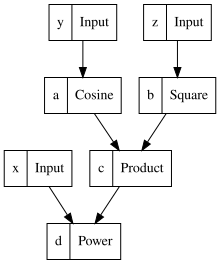

In [14]:
cg.plot(use_op_names=True)

Ahora en formato más "humano" con `use_op_names=False`

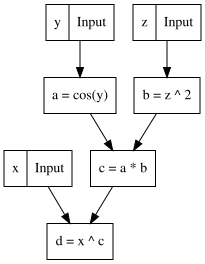

In [15]:
cg.plot(use_op_names=False)

Si cambiamos el parámetro `vertical=False` pasa a ser horizontal

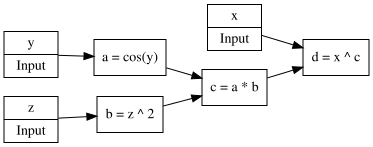

In [16]:
cg.plot(use_op_names=False,vertical=False)

In [19]:
class Sigmoid(Operation):
    FMT = "sigmoid(%s)"

    def forward(self, x):
        """1 / (1 + e^-x)"""
        return 1 / (1 + math.exp(-x))

    def backwards(self, x):
        """sigma'(x) = sigma(x) * (1 - sigma(x))"""
        s = self.forward(x)
        return s * (1 - s)


class Sum3(Operation):
    FMT = "%s + %s + %s"

    def forward(self, a, b, c):
        return a + b + c

    def backwards(self, a, b, c):
        # PISTA: derivada de una suma respecto de cada sumando
        # Devolvé una tupla con una derivada por cada entrada (el orden importa)
        return (1.0, 1.0, 1.0)


class Sub(Operation):
    FMT = "%s - %s"

    def forward(self, a, b):
        return a - b

    def backwards(self, a, b):
        return (1.0, -1.0)


# --- Prueba mínima: UNA neurona con dos entradas ---
# z = w1*x1 + w2*x2 + b ; out = sigmoid(z)
cg = ComputeGraph("x1", "x2", "w1", "w2", "b", debug=True)
cg["p1"]  = Product("x1", "w1")
cg["p2"]  = Product("x2", "w2")
cg["z"]   = Sum3("p1", "p2", "b")
cg["out"] = Sigmoid("z")

print(cg(x1=1.0, x2=2.0, w1=0.5, w2=-0.3, b=0.1))
print(cg.backwards())

Forward:	 x1 = 1.0
Forward:	 x2 = 2.0
Forward:	 w1 = 0.5
Forward:	 w2 = -0.3
Forward:	 b = 0.1
Forward:	 p1 = 0.5
Forward:	 p2 = -0.6
Forward:	 z = 2.7755575615628914e-17
Forward:	 out = 0.5
0.5
Backwards:	 out -> z = 1 * 0.25
Backwards:	 z -> p1 = 0.25 * 1.0
Backwards:	 z -> p2 = 0.25 * 1.0
Backwards:	 z -> b = 0.25 * 1.0
Backwards:	 p2 -> x2 = 0.25 * -0.3
Backwards:	 p2 -> w2 = 0.25 * 2.0
Backwards:	 p1 -> x1 = 0.25 * 0.5
Backwards:	 p1 -> w1 = 0.25 * 1.0
{'x1': 0.125, 'x2': -0.075, 'w1': 0.25, 'w2': 0.5, 'b': 0.25}


In [21]:
class Sum4(Operation):
    FMT = "%s + %s + %s + %s"

    def forward(self, a, b, c, d):
        return a + b + c + d

    def backwards(self, a, b, c, d):
        return (1.0, 1.0, 1.0, 1.0)


class HalfSquare(Operation):
    FMT = "0.5 * (%s)^2"

    def forward(self, x):
        return 0.5 * (x**2)

    def backwards(self, x):
        # d/dx [ 0.5 * x^2 ] = x
        return x


# --- Red completa 2-3-1 ---
# Entradas: observación, etiqueta y los 13 parámetros
nombres = ["x1", "x2", "y",
           "w1_11", "w1_12", "w1_21", "w1_22", "w1_31", "w1_32",
           "b1_1", "b1_2", "b1_3",
           "w2_1", "w2_2", "w2_3",
           "b2"]

cg = ComputeGraph(*nombres)   # debug=False para no inundar la consola

# Capa 1, neurona 1
cg["p11"] = Product("x1", "w1_11")
cg["p12"] = Product("x2", "w1_12")
cg["z1"]  = Sum3("p11", "p12", "b1_1")
cg["a1"]  = Sigmoid("z1")

# Neurona 2 de la capa 1 (productos p21, p22, z2, a2)
cg["p21"] = Product("x1", "w1_21")
cg["p22"] = Product("x2", "w1_22")
cg["z2"]  = Sum3("p21", "p22", "b1_2")
cg["a2"]  = Sigmoid("z2")

# Neurona 3 de la capa 1 (p31, p32, z3, a3)
cg["p31"] = Product("x1", "w1_31")
cg["p32"] = Product("x2", "w1_32")
cg["z3"]  = Sum3("p31", "p32", "b1_3")
cg["a3"]  = Sigmoid("z3")

# Capa 2: tres productos peso*activación, sumados con el sesgo
cg["q1"]   = Product("a1", "w2_1")
cg["q2"]   = Product("a2", "w2_2")
cg["q3"]   = Product("a3", "w2_3")
cg["z_out"] = Sum4("q1", "q2", "q3", "b2")
cg["y_hat"] = Sigmoid("z_out")

# Costo: J = 0.5 * (y_hat - y)^2
cg["err"] = Sub("y_hat", "y")
cg["J"]   = HalfSquare("err")

# --- Valores del enunciado ---
valores = dict(
    x1=1.8, x2=-3.4, y=5,
    w1_11=0.1,  w1_12=-0.5,
    w1_21=-0.3, w1_22=-0.9,
    w1_31=0.8,  w1_32=0.02,
    b1_1=0.1, b1_2=0.5, b1_3=0.8,
    w2_1=-0.4, w2_2=0.2, w2_3=-0.5,
    b2=0.7,
)

print("J =", cg(**valores))
grads = cg.backwards()
print(grads)

J = 10.023659920398922
{'x1': 0.048768840489075184, 'x2': -0.013869644956904964, 'y': 4.477423348400042, 'w1_11': 0.08573810285850478, 'w1_12': -0.16194974984384236, 'w1_21': -0.017841387049816616, 'w1_22': 0.033700397760764715, 'w1_31': 0.09232210809942484, 'w1_32': -0.17438620418780248, 'b1_1': 0.047632279365835986, 'b1_2': -0.009911881694342563, 'b1_3': 0.05129006005523602, 'w2_1': -0.9815515915249349, 'w2_2': -1.0650957031616428, 'w2_3': -1.0028045986791774, 'b2': -1.1170736711480758}


In [23]:
import numpy as np

# 1) Reorganizar los gradientes con la forma de cada parámetro
db2 = grads["b2"]                                   # PISTA: escalar, clave 'b2'

dw2 = np.array([grads["w2_1"], grads["w2_2"], grads["w2_3"]])          # PISTA: vector de 3

dw1 = np.array([
    [grads["w1_11"], grads["w1_12"]],
    [grads["w1_21"], grads["w1_22"]],
    [grads["w1_31"], grads["w1_32"]],
])                                                 # PISTA: matriz 3x2

print("db2:", db2)
print("dw2:", dw2, dw2.shape)
print("dw1:\n", dw1, dw1.shape)


# 2) Gradient checking por diferencias finitas sobre b2
def costo(**kw):
    return cg(**kw)

eps = 1e-6

val_mas   = dict(valores); val_mas["b2"]   += eps    # PISTA: + eps
val_menos = dict(valores); val_menos["b2"] -= eps    # PISTA: - eps

db2_numerico = (costo(**val_mas) - costo(**val_menos)) / (2 * eps)   # PISTA: denominador 2*eps

print("db2 autodiff :", db2)
print("db2 numerico :", db2_numerico)
print("diferencia   :", abs(db2 - db2_numerico))

db2: -1.1170736711480758
dw2: [-0.98155159 -1.0650957  -1.0028046 ] (3,)
dw1:
 [[ 0.0857381  -0.16194975]
 [-0.01784139  0.0337004 ]
 [ 0.09232211 -0.1743862 ]] (3, 2)
db2 autodiff : -1.1170736711480758
db2 numerico : -1.117073672673996
diferencia   : 1.525920279021875e-09


In [25]:
import numpy as np

# 1) Reorganizar los gradientes con la forma de cada parámetro
db2 = grads["b2"]                                   # PISTA: escalar, clave 'b2'

dw2 = np.array([grads["w2_1"], grads["w2_2"], grads["w2_3"]])          # PISTA: vector de 3

dw1 = np.array([
    [grads["w1_11"], grads["w1_12"]],
    [grads["w1_21"], grads["w1_22"]],
    [grads["w1_31"], grads["w1_32"]],
])                                                 # PISTA: matriz 3x2

print("db2:", db2)
print("dw2:", dw2, dw2.shape)
print("dw1:\n", dw1, dw1.shape)


# 2) Gradient checking por diferencias finitas sobre b2
def costo(**kw):
    return cg(**kw)

eps = 1e-6

val_mas   = dict(valores); val_mas["b2"]   += eps    # PISTA: + eps
val_menos = dict(valores); val_menos["b2"] -= eps    # PISTA: - eps

db2_numerico = (costo(**val_mas) - costo(**val_menos)) / (2 * eps)   # PISTA: denominador 2*eps

print("db2 autodiff :", db2)
print("db2 numerico :", db2_numerico)
print("diferencia   :", abs(db2 - db2_numerico))

db2: -1.1170736711480758
dw2: [-0.98155159 -1.0650957  -1.0028046 ] (3,)
dw1:
 [[ 0.0857381  -0.16194975]
 [-0.01784139  0.0337004 ]
 [ 0.09232211 -0.1743862 ]] (3, 2)
db2 autodiff : -1.1170736711480758
db2 numerico : -1.117073672673996
diferencia   : 1.525920279021875e-09
